# Task 2, Step 1: SigLIP Feature Caching

A frozen `google/siglip-base-patch16-224` encoder turns each image into 196 patch features of dimension 768, in $14\times14$ spatial order, with the final layer norm applied exactly once. Features are cached in FP16 with deterministic preprocessing, then the encoder leaves GPU memory before Qwen trains.

The caching itself runs in `kaggle_task2.ipynb`. This notebook checks and visualizes the real cached features.

In [1]:
import os, sys, json
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "task2_vlm_grounding")):
    root = os.path.dirname(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from task2_vlm_grounding.src.notebook_utils import *
setup_notebook()

In [2]:
from task2_vlm_grounding.src.feature_cache import FeatureStore, pool_features_2x2
import torch
with open(os.path.join(FEATURE_DIR, "index.json")) as f:
    cache_info = json.load(f)
store = FeatureStore(FEATURE_DIR)
manifest = load_manifest()
print("Encoder:", cache_info["model"])
display(pd.DataFrame([cache_info["stats"]]).round(2))
pd.DataFrame([cache_info["stats"]]).to_csv(f"{RESULTS_DIR}/feature_cache_stats.csv", index=False)
print("Array shape:", store.array.shape, "| dtype:", store.array.dtype)
assert store.array.shape[1:] == (196, 768) and store.array.dtype == np.float16
assert not np.isnan(store.array[:64].astype(np.float32)).any()

Encoder: google/siglip-base-patch16-224


,images,seconds,peak_gpu_mb,size_mb
0,9248,173.13,841.2,2655.19


Array shape: (9248, 196, 768) | dtype: float16


## 1.1 Feature magnitudes
The connector calibration in Step 3 compares magnitudes like these against text embeddings.

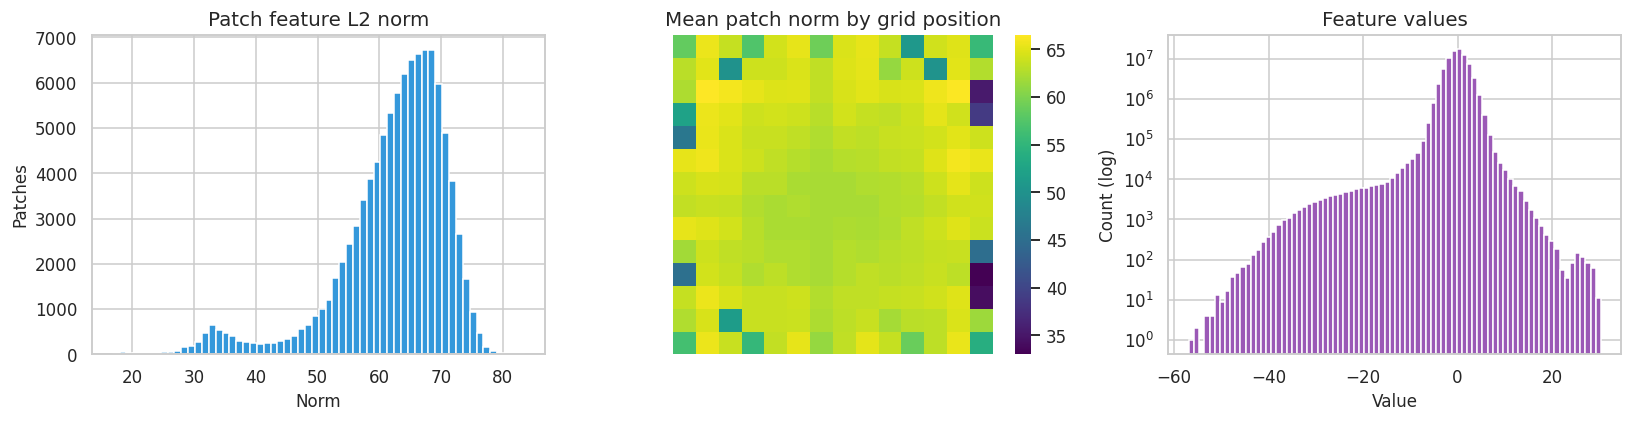

In [3]:
rng = np.random.default_rng(6304)
rows = np.sort(rng.choice(store.array.shape[0], size=min(512, store.array.shape[0]), replace=False))
sample = torch.from_numpy(np.array(store.array[rows])).float()
norms = sample.norm(dim=-1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(norms.flatten().numpy(), bins=60, color="#3498db", edgecolor="white")
axes[0].set(title="Patch feature L2 norm", xlabel="Norm", ylabel="Patches")
sns.heatmap(norms.mean(0).reshape(14, 14).numpy(), ax=axes[1], cmap="viridis", square=True, xticklabels=False, yticklabels=False)
axes[1].set_title("Mean patch norm by grid position")
axes[2].hist(sample.flatten().numpy(), bins=80, color="#9b59b6", edgecolor="white", log=True)
axes[2].set(title="Feature values", xlabel="Value", ylabel="Count (log)")
save_figure("task2_1_feature_statistics")

## 1.2 Do patch features keep spatial meaning?
**Selection rule:** the first three caption images in the manifest, with the query at the grid centre. Bright cells are patches most similar to the query. If 196 features were out of order, these maps would look scrambled.

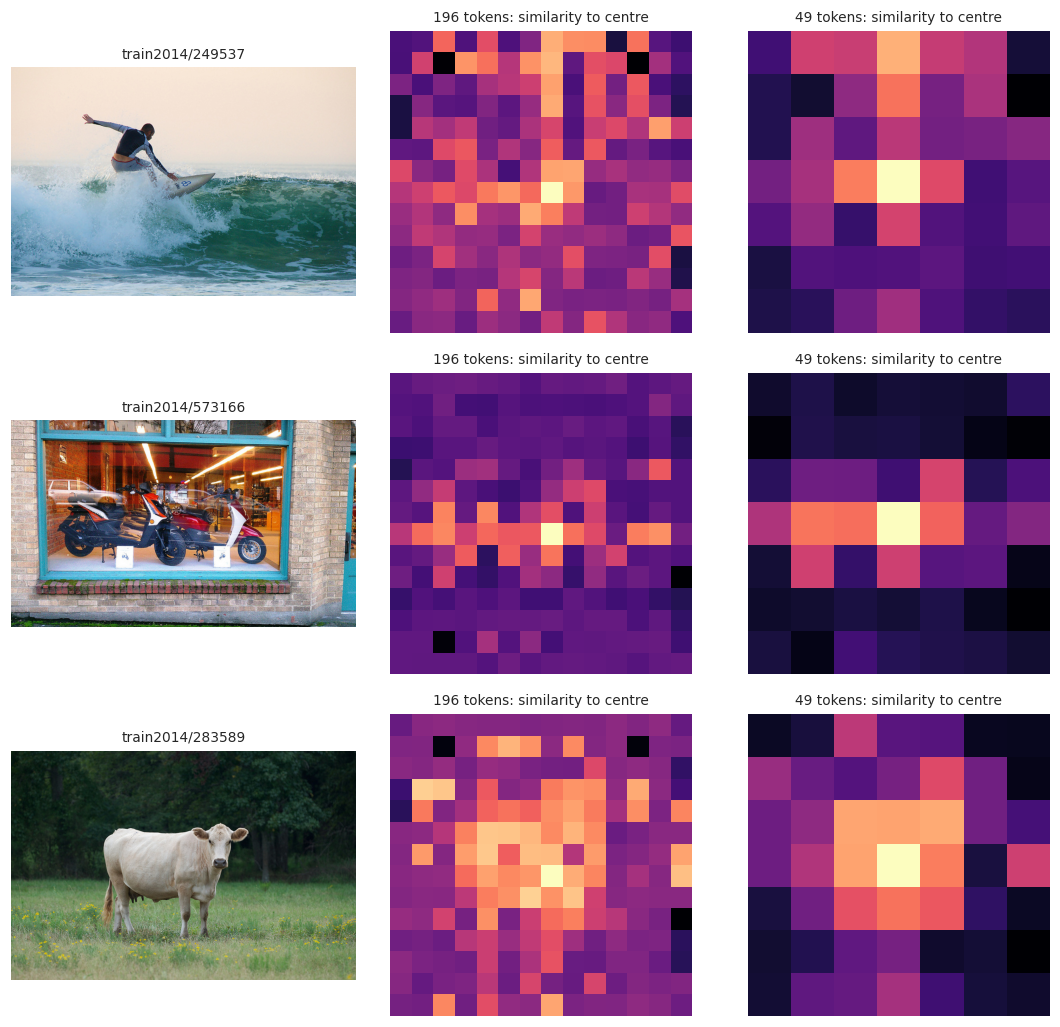

In [4]:
keys = [x["image"] for x in manifest["caption_train"][::3][:3]]
fig, axes = plt.subplots(3, 3, figsize=(10, 9.5))
for row, key in zip(axes, keys):
    feats = store.get(key).float()
    normalized = feats / feats.norm(dim=-1, keepdim=True)
    query = 7 * 14 + 7
    similarity = (normalized @ normalized[query]).reshape(14, 14).numpy()
    pooled = pool_features_2x2(feats)
    pooled = pooled / pooled.norm(dim=-1, keepdim=True)
    pooled_similarity = (pooled @ pooled[3 * 7 + 3]).reshape(7, 7).numpy()
    show_image(row[0], key, key)
    sns.heatmap(similarity, ax=row[1], cmap="magma", square=True, cbar=False, xticklabels=False, yticklabels=False)
    row[1].set_title("196 tokens: similarity to centre", fontsize=9)
    sns.heatmap(pooled_similarity, ax=row[2], cmap="magma", square=True, cbar=False, xticklabels=False, yticklabels=False)
    row[2].set_title("49 tokens: similarity to centre", fontsize=9)
save_figure("task2_1_patch_similarity")